In [1]:
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset

Setup Configuration

In [2]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
CHECKPOINTS_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

with open(PROJECT_DIR / "config.json", "r") as file:
    CONFIG = json.load(file)

GENERAL_CONFIG = CONFIG["general"]
DDPM_CONFIG = CONFIG["models"]["ddpm"]

random.seed(GENERAL_CONFIG["random_seed"])
np.random.seed(GENERAL_CONFIG["random_seed"])
torch.manual_seed(GENERAL_CONFIG["random_seed"])

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GENERAL_CONFIG["random_seed"])

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project:", GENERAL_CONFIG["project_name"])
print("Dataset:", GENERAL_CONFIG["dataset"])
print("Device:", device)
print("Timesteps:", DDPM_CONFIG["timesteps"])
print("Epochs:", DDPM_CONFIG["epochs"])
print("Batch Size:", GENERAL_CONFIG["batch_size"])

Project: Generative Models Comparison
Dataset: Fashion-MNIST
Device: cpu
Timesteps: 1000
Epochs: 50
Batch Size: 128


Load Dataset

In [5]:
print("Dataset Keys:", dataset.keys())

for key, value in dataset.items():
    if isinstance(value, torch.Tensor):
        print(f"{key}: {value.shape}")
    else:
        print(f"{key}: {type(value)}")

Dataset Keys: dict_keys(['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels'])
train_images: torch.Size([56000, 1, 28, 28])
train_labels: torch.Size([56000])
val_images: torch.Size([7000, 1, 28, 28])
val_labels: torch.Size([7000])
test_images: torch.Size([7000, 1, 28, 28])
test_labels: torch.Size([7000])


In [6]:
X_train = dataset["train_images"]
y_train = dataset["train_labels"]

X_val = dataset["val_images"]
y_val = dataset["val_labels"]

X_test = dataset["test_images"]
y_test = dataset["test_labels"]

print("Training Images:", X_train.shape)
print("Validation Images:", X_val.shape)
print("Testing Images:", X_test.shape)

Training Images: torch.Size([56000, 1, 28, 28])
Validation Images: torch.Size([7000, 1, 28, 28])
Testing Images: torch.Size([7000, 1, 28, 28])


Normalize Images

In [7]:
X_train = X_train.float() / 127.5 - 1.0
X_val = X_val.float() / 127.5 - 1.0
X_test = X_test.float() / 127.5 - 1.0

print("Training Pixel Range:")
print("Minimum:", X_train.min().item())
print("Maximum:", X_train.max().item())

print("\nValidation Pixel Range:")
print("Minimum:", X_val.min().item())
print("Maximum:", X_val.max().item())

Training Pixel Range:
Minimum: -1.0
Maximum: 1.0

Validation Pixel Range:
Minimum: -1.0
Maximum: 1.0


DataLoader

In [8]:
train_dataset = TensorDataset(X_train)
val_dataset = TensorDataset(X_val)
test_dataset = TensorDataset(X_test)

BATCH_SIZE = GENERAL_CONFIG["batch_size"]

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

Training Batches: 438
Validation Batches: 55
Testing Batches: 55


Diffusion Schedule

In [9]:
TIMESTEPS = DDPM_CONFIG["timesteps"]

BETA_START = DDPM_CONFIG["beta_start"]
BETA_END = DDPM_CONFIG["beta_end"]

betas = torch.linspace(
    BETA_START,
    BETA_END,
    TIMESTEPS
).to(device)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

sqrt_recip_alphas = torch.sqrt(1.0 / alphas)
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

posterior_variance = betas * (
    1.0 - torch.cat([
        torch.tensor([1.0]),
        alpha_bars[:-1]
    ]).to(device)
) / (1.0 - alpha_bars)

print("Timesteps:", TIMESTEPS)
print("Beta Shape:", betas.shape)
print("Alpha Bar Shape:", alpha_bars.shape)
print("Beta Range:", betas.min().item(), "-", betas.max().item())
print("Alpha Bar Range:", alpha_bars.min().item(), "-", alpha_bars.max().item())

Timesteps: 1000
Beta Shape: torch.Size([1000])
Alpha Bar Shape: torch.Size([1000])
Beta Range: 9.999999747378752e-05 - 0.0020000000949949026
Alpha Bar Range: 0.34969189763069153 - 0.9998999834060669


Forward Diffusion Function

In [10]:
def forward_diffusion(images, timesteps, noise=None):
    if noise is None:
        noise = torch.randn_like(images)

    sqrt_alpha_bar = sqrt_alpha_bars[timesteps].view(-1, 1, 1, 1)
    sqrt_one_minus_alpha_bar = sqrt_one_minus_alpha_bars[timesteps].view(-1, 1, 1, 1)

    noisy_images = (
        sqrt_alpha_bar * images
        + sqrt_one_minus_alpha_bar * noise
    )

    return noisy_images, noise

Test Forward Diffusion

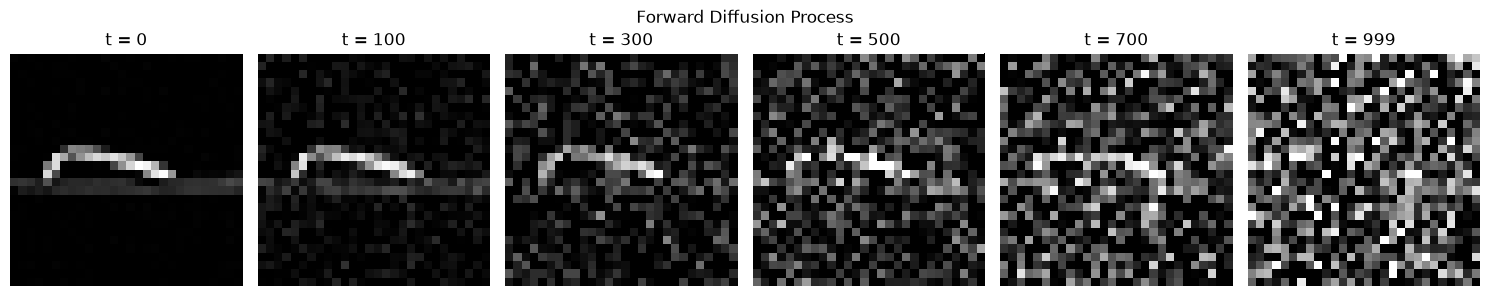

In [12]:
sample_image = X_train[0:1].to(device)

selected_timesteps = [0, 100, 300, 500, 700, 999]

fig, axes = plt.subplots(1, 6, figsize=(15, 3))

for ax, timestep in zip(axes, selected_timesteps):
    t = torch.tensor([timestep], device=device)

    noisy_image, _ = forward_diffusion(sample_image, t)

    ax.imshow(
        noisy_image.squeeze().cpu().numpy(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )
    ax.set_title(f"t = {timestep}")
    ax.axis("off")

plt.suptitle("Forward Diffusion Process")
plt.tight_layout()

plt.savefig(RESULTS_DIR / "ddpm_forward_diffusion.png", dpi=100)
plt.show()

Sinusoidal Time Embedding

In [13]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.embedding_dim = embedding_dim

    def forward(self, timesteps):
        half_dim = self.embedding_dim // 2

        embeddings = torch.log(
            torch.tensor(10000.0, device=timesteps.device)
        ) / (half_dim - 1)

        embeddings = torch.exp(
            torch.arange(half_dim, device=timesteps.device) * -embeddings
        )

        embeddings = timesteps.float().unsqueeze(1) * embeddings.unsqueeze(0)

        embeddings = torch.cat(
            [torch.sin(embeddings), torch.cos(embeddings)],
            dim=1
        )

        return embeddings

Residual Block

In [14]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

        self.time_mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_dim, out_channels)
        )

        self.conv2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.GroupNorm(8, out_channels)
        )

        self.shortcut = (
            nn.Conv2d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels
            else nn.Identity()
        )

        self.activation = nn.SiLU()

    def forward(self, x, time_embedding):
        residual = self.shortcut(x)

        x = self.conv1(x)

        time_features = self.time_mlp(time_embedding)
        x = x + time_features[:, :, None, None]

        x = self.conv2(x)

        return self.activation(x + residual)

Downsample dan Upsample Blocks

In [15]:
class DownsampleBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.conv = nn.Conv2d(
            channels,
            channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

    def forward(self, x):
        return self.conv(x)


class UpsampleBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

    def forward(self, x):
        return self.conv(x)

Build U-Net Architecture

In [16]:
class UNet(nn.Module):
    def __init__(self, config):
        super().__init__()

        channels = config["channels"]
        time_dim = channels[0] * 4

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(channels[0]),
            nn.Linear(channels[0], time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input_conv = nn.Conv2d(
            1, channels[0], kernel_size=3, padding=1
        )

        self.down1 = ResidualBlock(channels[0], channels[0], time_dim)
        self.downsample1 = DownsampleBlock(channels[0])

        self.down2 = ResidualBlock(channels[0], channels[1], time_dim)
        self.downsample2 = DownsampleBlock(channels[1])

        self.middle = ResidualBlock(channels[1], channels[2], time_dim)

        self.upsample1 = UpsampleBlock(channels[2], channels[1])
        self.up1 = ResidualBlock(channels[1] * 2, channels[1], time_dim)

        self.upsample2 = UpsampleBlock(channels[1], channels[0])
        self.up2 = ResidualBlock(channels[0] * 2, channels[0], time_dim)

        self.output = nn.Sequential(
            nn.Conv2d(channels[0], channels[0], kernel_size=3, padding=1),
            nn.SiLU(),
            nn.Conv2d(channels[0], 1, kernel_size=1)
        )

    def forward(self, x, timesteps):
        time_embedding = self.time_embedding(timesteps)

        x = self.input_conv(x)

        skip1 = self.down1(x, time_embedding)
        x = self.downsample1(skip1)

        skip2 = self.down2(x, time_embedding)
        x = self.downsample2(skip2)

        x = self.middle(x, time_embedding)

        x = self.upsample1(x)
        x = torch.cat([x, skip2], dim=1)
        x = self.up1(x, time_embedding)

        x = self.upsample2(x)
        x = torch.cat([x, skip1], dim=1)
        x = self.up2(x, time_embedding)

        return self.output(x)


unet = UNet(DDPM_CONFIG).to(device)

print(unet)

UNet(
  (time_embedding): Sequential(
    (0): SinusoidalTimeEmbedding()
    (1): Linear(in_features=64, out_features=256, bias=True)
    (2): SiLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
  )
  (input_conv): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (down1): ResidualBlock(
    (conv1): Sequential(
      (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
      (2): SiLU()
    )
    (time_mlp): Sequential(
      (0): SiLU()
      (1): Linear(in_features=256, out_features=64, bias=True)
    )
    (conv2): Sequential(
      (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
    )
    (shortcut): Identity()
    (activation): SiLU()
  )
  (downsample1): DownsampleBlock(
    (conv): Conv2d(64, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  )
  (down2): ResidualBlock(
    

Test U-Net Forward Pass

In [17]:
test_images = torch.randn(8, 1, 28, 28).to(device)
test_timesteps = torch.randint(0, TIMESTEPS, (8,)).to(device)

with torch.no_grad():
    predicted_noise = unet(test_images, test_timesteps)

print("Input Shape:", test_images.shape)
print("Timestep Shape:", test_timesteps.shape)
print("Predicted Noise Shape:", predicted_noise.shape)


Input Shape: torch.Size([8, 1, 28, 28])
Timestep Shape: torch.Size([8])
Predicted Noise Shape: torch.Size([8, 1, 28, 28])


Setup Training

In [18]:
criterion = nn.MSELoss()

learning_rate = DDPM_CONFIG["learning_rate"]

optimizer = optim.Adam(
    unet.parameters(),
    lr=learning_rate
)

EPOCHS = DDPM_CONFIG["epochs"]

train_losses = []
val_losses = []

checkpoint_path = CHECKPOINTS_DIR / "ddpm.pth"

print("Learning Rate:", learning_rate)
print("Epochs:", EPOCHS)
print("Loss Function:", criterion)
print("Checkpoint Path:", checkpoint_path)

Learning Rate: 0.0002
Epochs: 50
Loss Function: MSELoss()
Checkpoint Path: d:\generative-models-comparison\checkpoints\ddpm.pth


Train DDPM

In [ ]:
for epoch in range(EPOCHS):
    unet.train()
    total_train_loss = 0

    for (images,) in train_loader:
        images = images.to(device)
        batch_size = images.size(0)

        # Sample random timesteps
        timesteps = torch.randint(
            0, TIMESTEPS, (batch_size,), device=device
        )

        # Add Gaussian noise
        noisy_images, noise = forward_diffusion(images, timesteps)

        # Predict noise
        predicted_noise = unet(noisy_images, timesteps)

        # Calculate loss
        loss = criterion(predicted_noise, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation
    unet.eval()
    total_val_loss = 0

    with torch.no_grad():
        for (images,) in val_loader:
            images = images.to(device)
            batch_size = images.size(0)

            timesteps = torch.randint(
                0, TIMESTEPS, (batch_size,), device=device
            )

            noisy_images, noise = forward_diffusion(images, timesteps)
            predicted_noise = unet(noisy_images, timesteps)

            val_loss = criterion(predicted_noise, noise)
            total_val_loss += val_loss.item()

    avg_val_loss = total_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    # Save checkpoint every 10 epochs
    if (epoch + 1) % 10 == 0:
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": unet.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_losses": train_losses,
            "val_losses": val_losses
        }, checkpoint_path)

        print(
            f"Epoch [{epoch + 1}/{EPOCHS}] "
            f"Train Loss: {avg_train_loss:.6f} "
            f"Val Loss: {avg_val_loss:.6f}"
        )